In [1]:
# ==========================================
# CREDIT CARD FRAUD DETECTION
# STEP 02: DATASET INSPECTION
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ==========================================
# LOAD DATASET
# ==========================================

import os

if os.path.exists("../data/credit_card_fraud_10k.csv"):
    DATA_PATH = "../data/credit_card_fraud_10k.csv"
elif os.path.exists("data/credit_card_fraud_10k.csv"):
    DATA_PATH = "data/credit_card_fraud_10k.csv"
else:
    raise FileNotFoundError("Dataset not found! Check your data folder.")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (10000, 10)


In [3]:
# ==========================================
# LAST 5 RECORDS
# ==========================================

display(df.tail())

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
9995,9996,350.91,22,Food,0,0,99,4,37,0
9996,9997,410.04,5,Clothing,0,0,70,3,25,0
9997,9998,527.75,21,Electronics,0,0,44,2,45,0
9998,9999,91.20,2,Electronics,0,0,38,0,37,0
9999,10000,44.06,2,Clothing,0,0,38,0,66,0


In [4]:
# ==========================================
# DATASET INFORMATION
# ==========================================

print("Dataset Information:\n")

df.info()

Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 851.2 KB


In [5]:
# ==========================================
# STATISTICAL SUMMARY
# ==========================================

display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
amount,10000.0,NaN,NaN,NaN,175.949849,175.392827,0.0,50.905,122.095,242.48,1471.04
transaction_hour,10000.0,NaN,NaN,NaN,11.5933,6.922708,0.0,6.0,12.0,18.0,23.0
merchant_category,10000,5,Food,2093,NaN,NaN,NaN,NaN,NaN,NaN,NaN
foreign_transaction,10000.0,NaN,NaN,NaN,0.0978,0.297059,0.0,0.0,0.0,0.0,1.0
location_mismatch,10000.0,NaN,NaN,NaN,0.0857,0.279935,0.0,0.0,0.0,0.0,1.0
device_trust_score,10000.0,NaN,NaN,NaN,61.7989,21.487053,25.0,43.0,62.0,80.0,99.0
velocity_last_24h,10000.0,NaN,NaN,NaN,2.0089,1.432559,0.0,1.0,2.0,3.0,9.0
cardholder_age,10000.0,NaN,NaN,NaN,43.4687,14.979147,18.0,30.0,44.0,56.0,69.0
is_fraud,10000.0,NaN,NaN,NaN,0.0151,0.121957,0.0,0.0,0.0,0.0,1.0


In [6]:
# ==========================================
# MISSING VALUES
# ==========================================

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

display(missing_report)

,Missing Values,Missing Percentage
transaction_id,0,0.0
amount,0,0.0
transaction_hour,0,0.0
merchant_category,0,0.0
foreign_transaction,0,0.0
location_mismatch,0,0.0
device_trust_score,0,0.0
velocity_last_24h,0,0.0
cardholder_age,0,0.0
is_fraud,0,0.0


In [7]:
# ==========================================
# DUPLICATE RECORDS
# ==========================================

print("Total Duplicate Records:", df.duplicated().sum())

print("Dataset Shape:", df.shape)

Total Duplicate Records: 0
Dataset Shape: (10000, 10)


In [8]:
# ==========================================
# FRAUD DISTRIBUTION
# ==========================================

print("Fraud Distribution:\n")

display(df['is_fraud'].value_counts())

print("\nFraud Percentage:\n")

display(
    df['is_fraud'].value_counts(normalize=True) * 100
)

Fraud Distribution:



is_fraud
0    9849
1     151
Name: count, dtype: int64


Fraud Percentage:



is_fraud
0    98.49
1     1.51
Name: proportion, dtype: float64

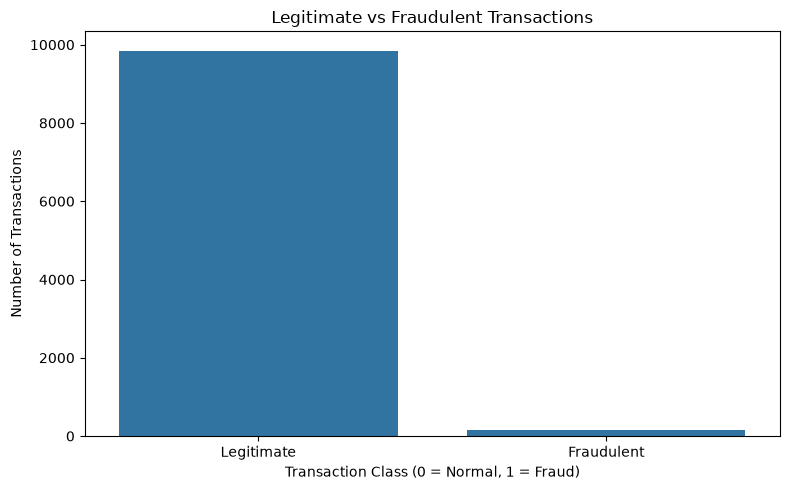

In [9]:
# ==========================================
# FRAUD DISTRIBUTION VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='is_fraud'
)

plt.title('Legitimate vs Fraudulent Transactions')
plt.xlabel('Transaction Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.xticks([0, 1], ['Legitimate', 'Fraudulent'])

plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# STEP 03: DATA CLEANING & PREPROCESSING
# ==========================================

df_clean = df.copy()

print("Working dataset created successfully!")
print("Original Shape:", df.shape)
print("Working Shape:", df_clean.shape)

Working dataset created successfully!
Original Shape: (10000, 10)
Working Shape: (10000, 10)


In [11]:
# ==========================================
# COLUMN NAME VALIDATION
# ==========================================

print("Column Names:\n")

for column in df_clean.columns:
    print(column)

Column Names:

transaction_id
amount
transaction_hour
merchant_category
foreign_transaction
location_mismatch
device_trust_score
velocity_last_24h
cardholder_age
is_fraud


In [12]:
# ==========================================
# UNIQUE VALUES
# ==========================================

print("Unique Values in Each Column:\n")

for column in df_clean.columns:
    print(f"{column}: {df_clean[column].nunique()}")

Unique Values in Each Column:

transaction_id: 10000
amount: 8788
transaction_hour: 24
merchant_category: 5
foreign_transaction: 2
location_mismatch: 2
device_trust_score: 75
velocity_last_24h: 10
cardholder_age: 52
is_fraud: 2


In [13]:
# ==========================================
# CATEGORICAL VALUE INSPECTION
# ==========================================

categorical_columns = df_clean.select_dtypes(
    include=['object', 'str', 'category']
).columns

for column in categorical_columns:

    print(f"\nColumn: {column}")

    print(df_clean[column].value_counts())


Column: merchant_category
merchant_category
Food           2093
Clothing       2050
Travel         1990
Grocery        1944
Electronics    1923
Name: count, dtype: int64


In [14]:
# ==========================================
# BINARY COLUMN VALIDATION
# ==========================================

binary_columns = [
    'foreign_transaction',
    'location_mismatch',
    'is_fraud'
]

for column in binary_columns:

    print(f"\n{column}")

    print(df_clean[column].value_counts().sort_index())

    print("Unique Values:", df_clean[column].unique())


foreign_transaction
foreign_transaction
0    9022
1     978
Name: count, dtype: int64
Unique Values: [0 1]

location_mismatch
location_mismatch
0    9143
1     857
Name: count, dtype: int64
Unique Values: [0 1]

is_fraud
is_fraud
0    9849
1     151
Name: count, dtype: int64
Unique Values: [0 1]


In [15]:
# ==========================================
# NUMERICAL RANGE VALIDATION
# ==========================================

numeric_columns = [
    'amount',
    'transaction_hour',
    'device_trust_score',
    'velocity_last_24h',
    'cardholder_age'
]

display(
    df_clean[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
amount,10000.0,175.949849,175.392827,0.0,50.905,122.095,242.48,1471.04
transaction_hour,10000.0,11.593300,6.922708,0.0,6.000,12.000,18.00,23.00
device_trust_score,10000.0,61.798900,21.487053,25.0,43.000,62.000,80.00,99.00
velocity_last_24h,10000.0,2.008900,1.432559,0.0,1.000,2.000,3.00,9.00
cardholder_age,10000.0,43.468700,14.979147,18.0,30.000,44.000,56.00,69.00


In [16]:
# ==========================================
# TRANSACTION ID VALIDATION
# ==========================================

print(
    "Total Transaction IDs:",
    df_clean['transaction_id'].count()
)

print(
    "Unique Transaction IDs:",
    df_clean['transaction_id'].nunique()
)

print(
    "Duplicate Transaction IDs:",
    df_clean['transaction_id'].duplicated().sum()
)

Total Transaction IDs: 10000
Unique Transaction IDs: 10000
Duplicate Transaction IDs: 0


In [17]:
# ==========================================
# INVALID VALUE CHECK
# ==========================================

print("Invalid Amounts:",
      (df_clean['amount'] < 0).sum())

print("Invalid Transaction Hours:",
      (~df_clean['transaction_hour'].between(0, 23)).sum())

print("Invalid Device Trust Scores:",
      (~df_clean['device_trust_score'].between(0, 100)).sum())

print("Invalid Cardholder Ages:",
      (~df_clean['cardholder_age'].between(18, 100)).sum())

print("Invalid Target Values:",
      (~df_clean['is_fraud'].isin([0, 1])).sum())

Invalid Amounts: 0
Invalid Transaction Hours: 0
Invalid Device Trust Scores: 0
Invalid Cardholder Ages: 0
Invalid Target Values: 0


In [18]:
# ==========================================
# FINAL DATA QUALITY REPORT
# ==========================================

quality_report = pd.DataFrame({
    'Column': df_clean.columns,
    'Data Type': df_clean.dtypes.astype(str).values,
    'Missing Values': df_clean.isnull().sum().values,
    'Unique Values': df_clean.nunique().values
})

display(quality_report)

print("\nFinal Dataset Shape:", df_clean.shape)

,Column,Data Type,Missing Values,Unique Values
0,transaction_id,int64,0,10000
1,amount,float64,0,8788
2,transaction_hour,int64,0,24
3,merchant_category,str,0,5
4,foreign_transaction,int64,0,2
5,location_mismatch,int64,0,2
6,device_trust_score,int64,0,75
7,velocity_last_24h,int64,0,10
8,cardholder_age,int64,0,52
9,is_fraud,int64,0,2



Final Dataset Shape: (10000, 10)


In [19]:
# ==========================================
# STEP 04: EXPLORATORY DATA ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14

print("EDA environment configured successfully!")

EDA environment configured successfully!


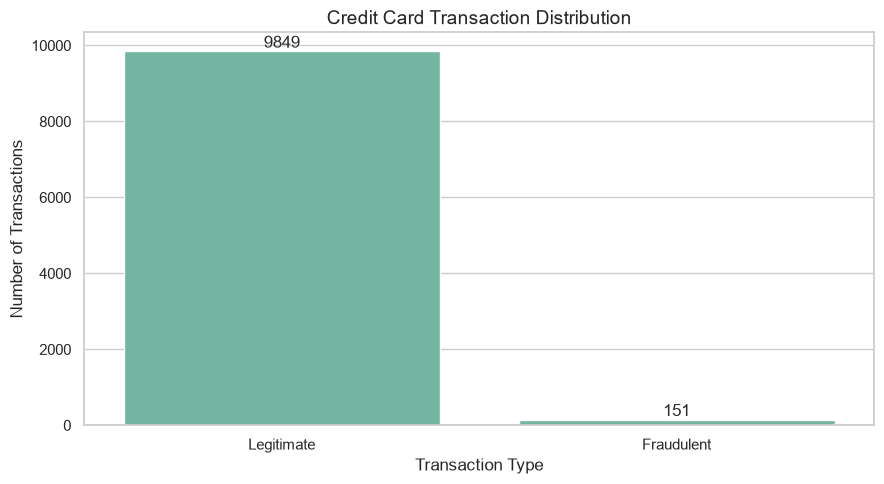

In [20]:
# ==========================================
# FRAUD DISTRIBUTION
# ==========================================

fraud_counts = df_clean['is_fraud'].value_counts()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=['Legitimate', 'Fraudulent'],
    y=[fraud_counts[0], fraud_counts[1]]
)

plt.title('Credit Card Transaction Distribution')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

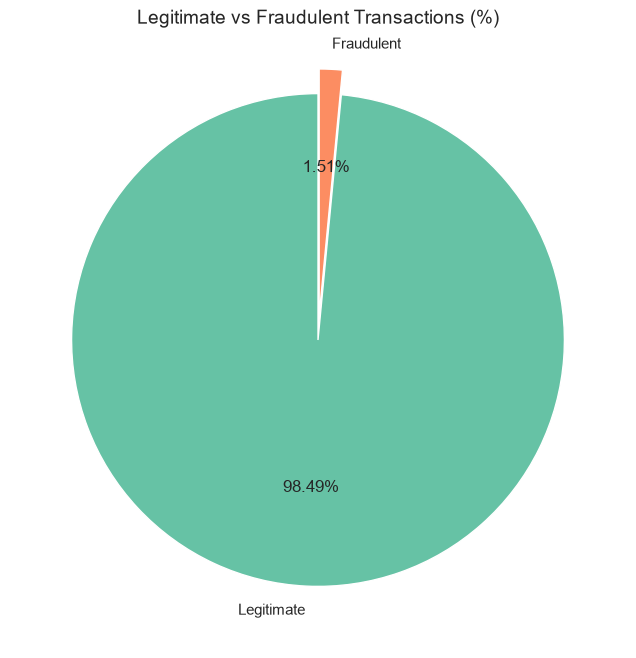

In [21]:
# ==========================================
# FRAUD PERCENTAGE DISTRIBUTION
# ==========================================

fraud_percentage = (
    df_clean['is_fraud']
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(8, 8))

plt.pie(
    fraud_percentage,
    labels=['Legitimate', 'Fraudulent'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0, 0.1)
)

plt.title('Legitimate vs Fraudulent Transactions (%)')

plt.show()

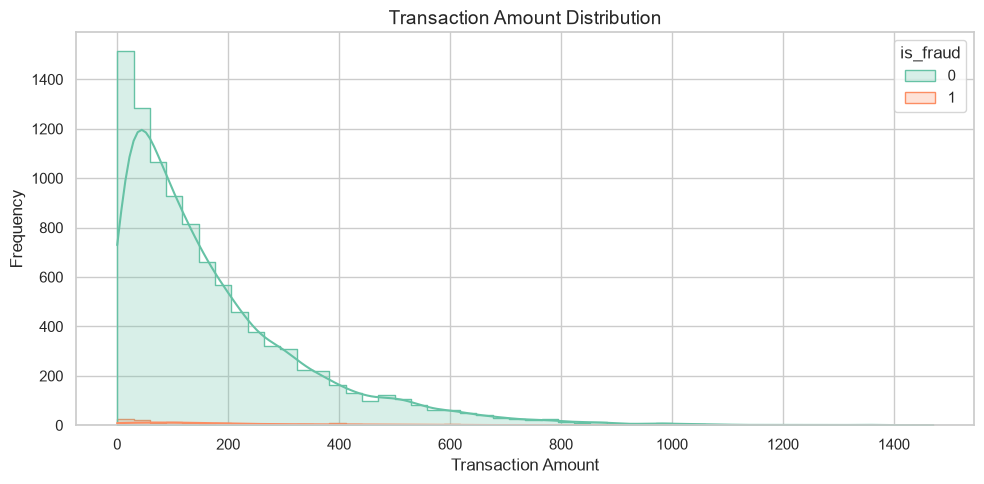

In [22]:
# ==========================================
# TRANSACTION AMOUNT DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='amount',
    hue='is_fraud',
    bins=50,
    kde=True,
    element='step'
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

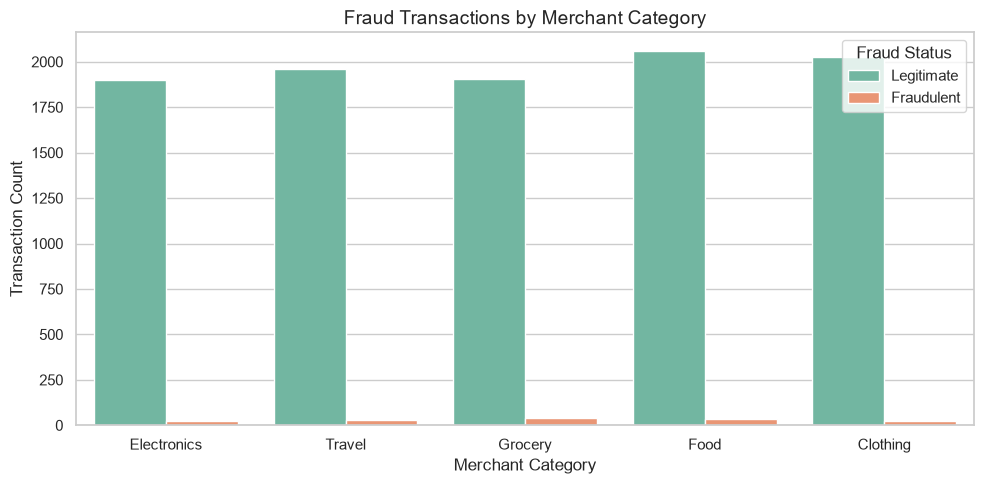

In [23]:
# ==========================================
# FRAUD BY MERCHANT CATEGORY
# ==========================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x='merchant_category',
    hue='is_fraud'
)

plt.title('Fraud Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Transaction Count')

plt.legend(
    title='Fraud Status',
    labels=['Legitimate', 'Fraudulent']
)

plt.tight_layout()
plt.show()

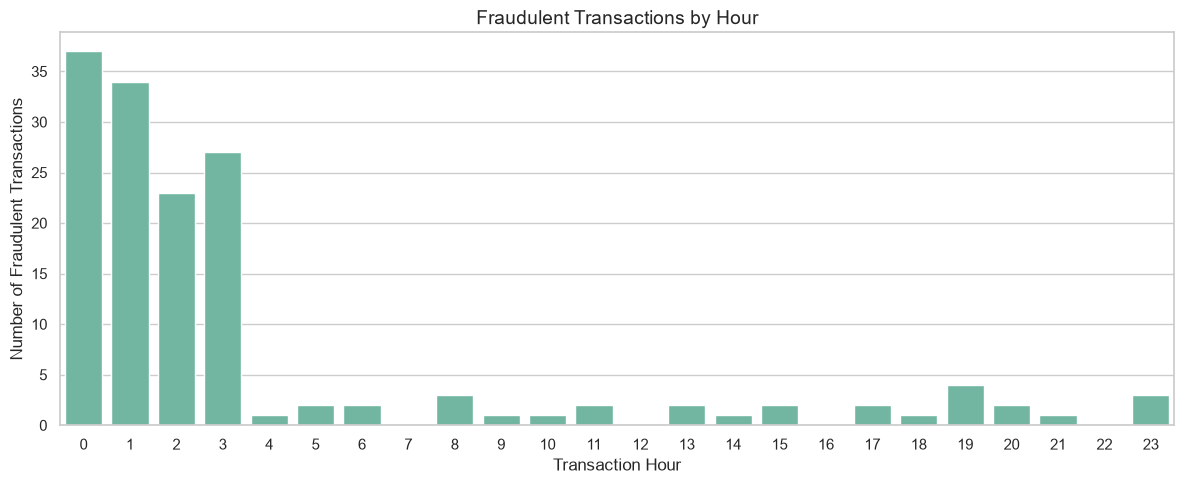

In [24]:
# ==========================================
# FRAUD BY TRANSACTION HOUR
# ==========================================

hourly_fraud = (
    df_clean.groupby('transaction_hour')['is_fraud']
    .sum()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_fraud.index,
    y=hourly_fraud.values
)

plt.title('Fraudulent Transactions by Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Number of Fraudulent Transactions')

plt.tight_layout()
plt.show()

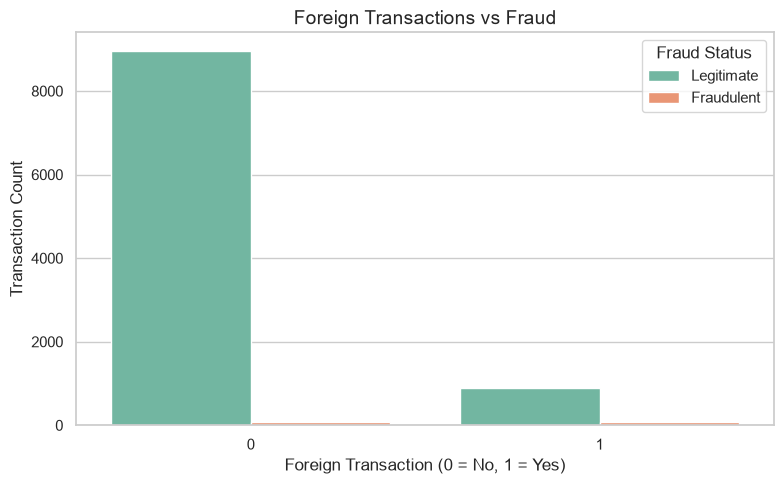

In [25]:
# ==========================================
# FOREIGN TRANSACTIONS VS FRAUD
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='foreign_transaction',
    hue='is_fraud'
)

plt.title('Foreign Transactions vs Fraud')
plt.xlabel('Foreign Transaction (0 = No, 1 = Yes)')
plt.ylabel('Transaction Count')

plt.legend(
    title='Fraud Status',
    labels=['Legitimate', 'Fraudulent']
)

plt.tight_layout()
plt.show()

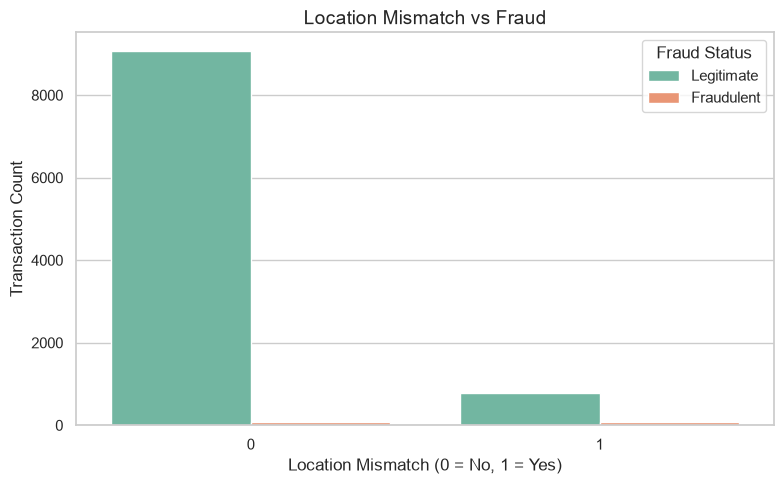

In [26]:
# ==========================================
# LOCATION MISMATCH VS FRAUD
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='location_mismatch',
    hue='is_fraud'
)

plt.title('Location Mismatch vs Fraud')
plt.xlabel('Location Mismatch (0 = No, 1 = Yes)')
plt.ylabel('Transaction Count')

plt.legend(
    title='Fraud Status',
    labels=['Legitimate', 'Fraudulent']
)

plt.tight_layout()
plt.show()

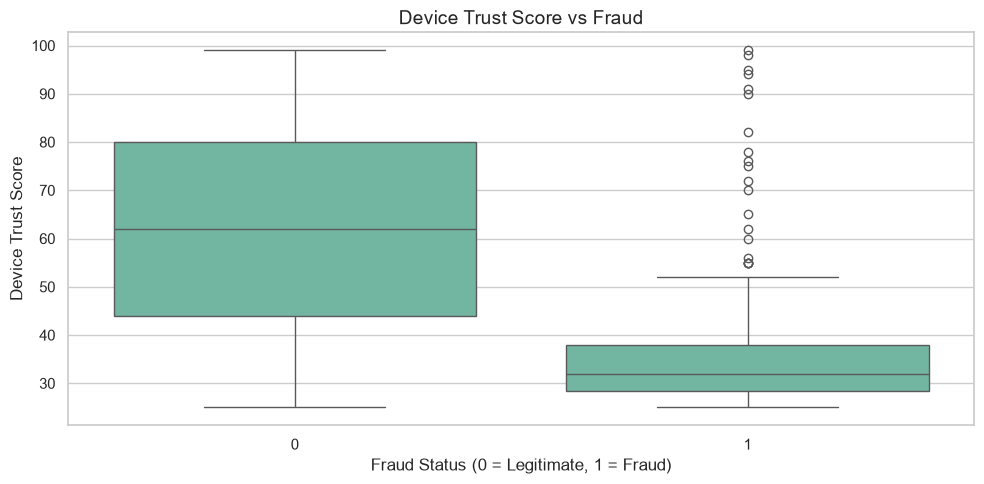

In [27]:
# ==========================================
# DEVICE TRUST SCORE VS FRAUD
# ==========================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='is_fraud',
    y='device_trust_score'
)

plt.title('Device Trust Score vs Fraud')
plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Device Trust Score')

plt.tight_layout()
plt.show()

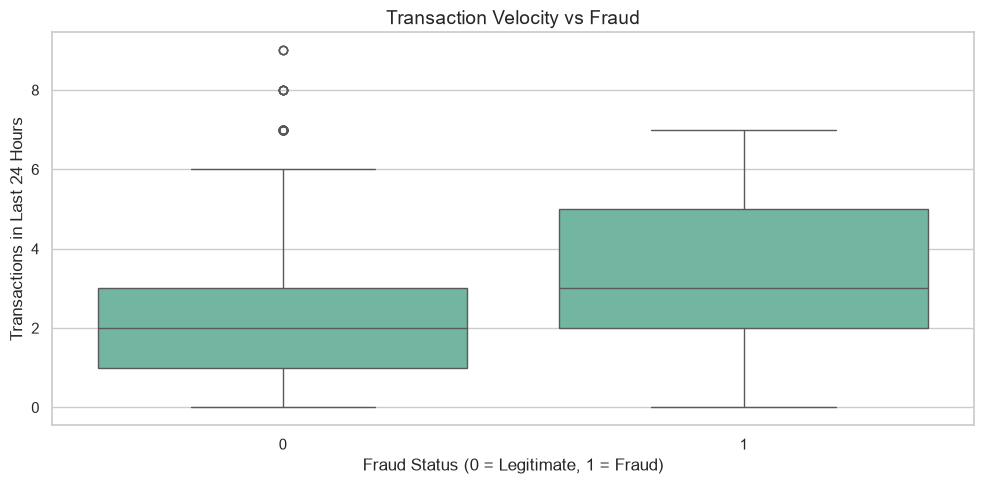

In [28]:
# ==========================================
# TRANSACTION VELOCITY VS FRAUD
# ==========================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='is_fraud',
    y='velocity_last_24h'
)

plt.title('Transaction Velocity vs Fraud')
plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transactions in Last 24 Hours')

plt.tight_layout()
plt.show()

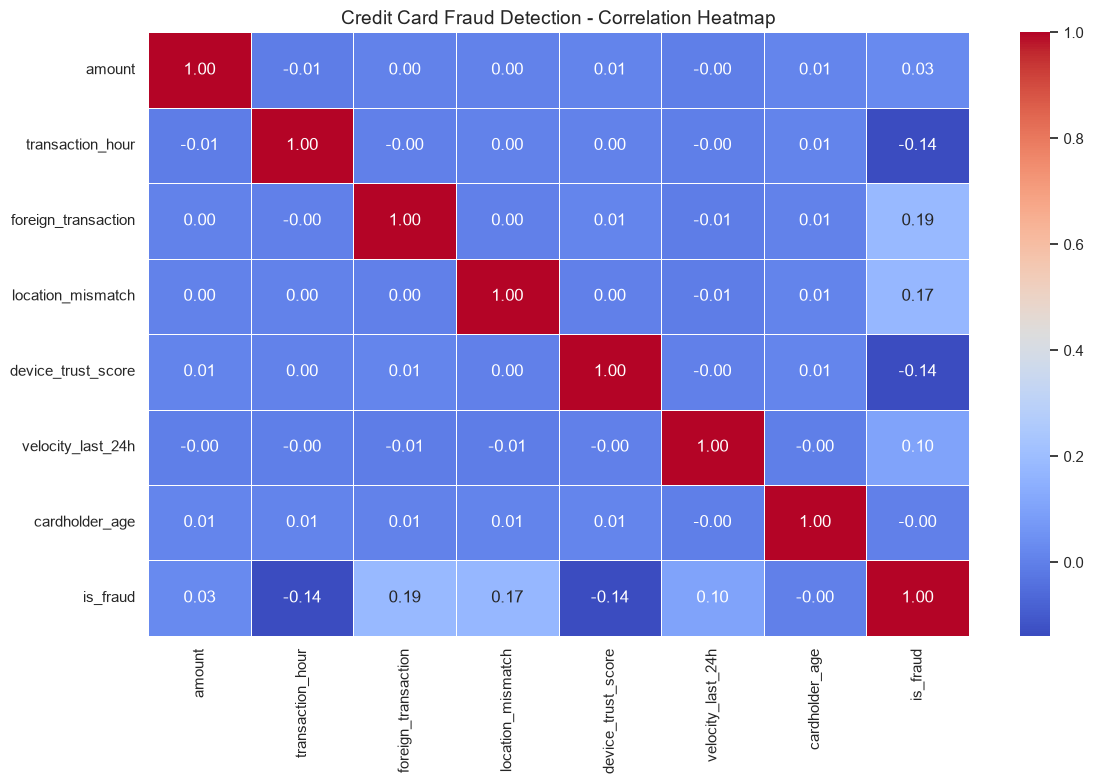

In [29]:
# ==========================================
# CORRELATION ANALYSIS
# ==========================================

correlation_data = df_clean.select_dtypes(
    include=np.number
).drop(columns=['transaction_id'])

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Credit Card Fraud Detection - Correlation Heatmap')

plt.tight_layout()
plt.show()

In [30]:
# ==========================================
# FRAUD RATE BY MERCHANT CATEGORY
# ==========================================

merchant_fraud_rate = (
    df_clean.groupby('merchant_category')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

merchant_fraud_rate.columns = [
    'Total Transactions',
    'Fraud Transactions',
    'Fraud Rate'
]

merchant_fraud_rate['Fraud Rate'] *= 100

display(
    merchant_fraud_rate.sort_values(
        by='Fraud Rate',
        ascending=False
    )
)

,Total Transactions,Fraud Transactions,Fraud Rate
merchant_category,,,
Grocery,1944,39,2.006173
Food,2093,35,1.672241
Travel,1990,29,1.457286
Electronics,1923,24,1.248050
Clothing,2050,24,1.170732


In [31]:
# ==========================================
# FRAUD RATE BY TRANSACTION HOUR
# ==========================================

hour_analysis = (
    df_clean.groupby('transaction_hour')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

hour_analysis.columns = [
    'Total Transactions',
    'Fraud Cases',
    'Fraud Rate'
]

hour_analysis['Fraud Rate'] *= 100

display(
    hour_analysis.sort_values(
        by='Fraud Rate',
        ascending=False
    )
)

,Total Transactions,Fraud Cases,Fraud Rate
transaction_hour,,,
0,417,37,8.872902
1,425,34,8.000000
3,425,27,6.352941
2,385,23,5.974026
19,421,4,0.950119
23,419,3,0.715990
8,424,3,0.707547
11,385,2,0.519481
6,413,2,0.484262


In [32]:
# ==========================================
# NUMERICAL FEATURES VS FRAUD
# ==========================================

features = [
    'amount',
    'device_trust_score',
    'velocity_last_24h',
    'cardholder_age'
]

for feature in features:

    print(f"\n{feature.upper()}")

    display(
        df_clean.groupby('is_fraud')[feature]
        .agg(['mean', 'median', 'min', 'max'])
    )


AMOUNT


,mean,median,min,max
is_fraud,,,,
0,175.333015,122.11,0.00,1471.04
1,216.182980,118.94,0.11,1185.07



DEVICE_TRUST_SCORE


,mean,median,min,max
is_fraud,,,,
0,62.165804,62.0,25,99
1,37.867550,32.0,25,99



VELOCITY_LAST_24H


,mean,median,min,max
is_fraud,,,,
0,1.990557,2.0,0,9
1,3.205298,3.0,0,7



CARDHOLDER_AGE


,mean,median,min,max
is_fraud,,,,
0,43.469794,44.0,18,69
1,43.397351,44.0,18,69


In [33]:
# ==========================================
# FOREIGN TRANSACTION FRAUD RATE
# ==========================================

foreign_analysis = (
    df_clean.groupby('foreign_transaction')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

foreign_analysis.columns = [
    'Total Transactions',
    'Fraud Cases',
    'Fraud Rate'
]

foreign_analysis['Fraud Rate'] *= 100

display(foreign_analysis)

,Total Transactions,Fraud Cases,Fraud Rate
foreign_transaction,,,
0,9022,69,0.764797
1,978,82,8.384458


In [34]:
# ==========================================
# LOCATION MISMATCH FRAUD RATE
# ==========================================

location_analysis = (
    df_clean.groupby('location_mismatch')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

location_analysis.columns = [
    'Total Transactions',
    'Fraud Cases',
    'Fraud Rate'
]

location_analysis['Fraud Rate'] *= 100

display(location_analysis)

,Total Transactions,Fraud Cases,Fraud Rate
location_mismatch,,,
0,9143,79,0.864049
1,857,72,8.401400


In [35]:
# ==========================================
# STEP 05: FEATURE ENGINEERING
# ==========================================

df_model = df_clean.copy()

# Remove transaction identifier
df_model.drop(
    columns=['transaction_id'],
    inplace=True
)

# Cyclical encoding of transaction hour
df_model['hour_sin'] = np.sin(
    2 * np.pi * df_model['transaction_hour'] / 24
)

df_model['hour_cos'] = np.cos(
    2 * np.pi * df_model['transaction_hour'] / 24
)

# Remove original hour after cyclical encoding
df_model.drop(
    columns=['transaction_hour'],
    inplace=True
)

print("Feature engineering completed!")

print("Original Shape:", df_clean.shape)
print("Model Dataset Shape:", df_model.shape)

display(df_model.head())

Feature engineering completed!
Original Shape: (10000, 10)
Model Dataset Shape: (10000, 10)


,amount,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud,hour_sin,hour_cos
0,84.47,Electronics,0,0,66,3,40,0,-0.500000,0.866025
1,541.82,Travel,1,0,87,1,64,0,0.707107,0.707107
2,237.01,Grocery,0,0,49,1,61,0,-0.965926,-0.258819
3,164.33,Grocery,0,1,72,3,34,0,0.866025,0.500000
4,30.53,Food,0,0,79,0,44,0,-0.707107,-0.707107


In [36]:
# ==========================================
# SEPARATE FEATURES AND TARGET
# ==========================================

X = df_model.drop(columns=['is_fraud'])

y = df_model['is_fraud']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
display(y.value_counts())

Features Shape: (10000, 9)
Target Shape: (10000,)

Target Distribution:


is_fraud
0    9849
1     151
Name: count, dtype: int64

In [37]:
# ==========================================
# IDENTIFY FEATURE TYPES
# ==========================================

categorical_features = [
    'merchant_category'
]

binary_features = [
    'foreign_transaction',
    'location_mismatch'
]

numerical_features = [
    'amount',
    'device_trust_score',
    'velocity_last_24h',
    'cardholder_age',
    'hour_sin',
    'hour_cos'
]

print("Categorical Features:", categorical_features)
print("Binary Features:", binary_features)
print("Numerical Features:", numerical_features)

print("\nTotal Features:",
      len(categorical_features) +
      len(binary_features) +
      len(numerical_features))

Categorical Features: ['merchant_category']
Binary Features: ['foreign_transaction', 'location_mismatch']
Numerical Features: ['amount', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'hour_sin', 'hour_cos']

Total Features: 9


In [38]:
# ==========================================
# TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts())

print("\nTesting Target Distribution:")
display(y_test.value_counts())

Training Features: (8000, 9)
Testing Features: (2000, 9)

Training Target Distribution:


is_fraud
0    7879
1     121
Name: count, dtype: int64


Testing Target Distribution:


is_fraud
0    1970
1      30
Name: count, dtype: int64

In [39]:
# ==========================================
# VERIFY TRAIN TEST DISTRIBUTION
# ==========================================

train_distribution = (
    y_train.value_counts(normalize=True) * 100
)

test_distribution = (
    y_test.value_counts(normalize=True) * 100
)

distribution_comparison = pd.DataFrame({
    'Training Percentage': train_distribution,
    'Testing Percentage': test_distribution
})

display(distribution_comparison)

,Training Percentage,Testing Percentage
is_fraud,,
0,98.4875,98.5
1,1.5125,1.5


In [40]:
# ==========================================
# DATA LEAKAGE CHECK
# ==========================================

print("Transaction ID in Features:",
      'transaction_id' in X_train.columns)

print("Target in Features:",
      'is_fraud' in X_train.columns)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Overlapping Indices:",
      len(set(X_train.index).intersection(set(X_test.index))))

Transaction ID in Features: False
Target in Features: False
Training Records: 8000
Testing Records: 2000
Overlapping Indices: 0


In [53]:
import sys

print("Python Executable:")
print(sys.executable)

print("\nPython Version:")
print(sys.version)

Python Executable:
C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\python.exe

Python Version:
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [54]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "ensurepip", "--upgrade"],
    capture_output=True,
    text=True
)

print("Return Code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return Code: 0
Looking in links: c:\Users\PRITWISH\AppData\Local\Temp\tmppi3wyxze




In [55]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--upgrade",
        "--force-reinstall",
        "pip"
    ],
    capture_output=True,
    text=True
)

print("Return Code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return Code: 1

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\__main__.py", line 22, in <module>
    from pip._internal.cli.main import main as _main
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\main.py", line 11, in <module>
    from pip._internal.cli.autocompletion import autocomplete
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\autocompletion.py", line 12, in <module>
    from pip._internal.cli.main_parser import create_main_parser
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\main_parser.py", line 9, in <module>
    from pip._internal.build_env import get_runnable_pip
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib

In [56]:
import sys
import subprocess

subprocess.run(
    [sys.executable, "-m", "pip", "--version"],
    check=True
)

CalledProcessError: Command '['C:\\Users\\PRITWISH\\AppData\\Local\\Programs\\Python\\Python313\\python.exe', '-m', 'pip', '--version']' returned non-zero exit status 1.

In [57]:
import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "imbalanced-learn"
    ],
    check=True
)

CalledProcessError: Command '['C:\\Users\\PRITWISH\\AppData\\Local\\Programs\\Python\\Python313\\python.exe', '-m', 'pip', 'install', 'imbalanced-learn']' returned non-zero exit status 1.

NameError: name 'y_train_resampled' is not defined

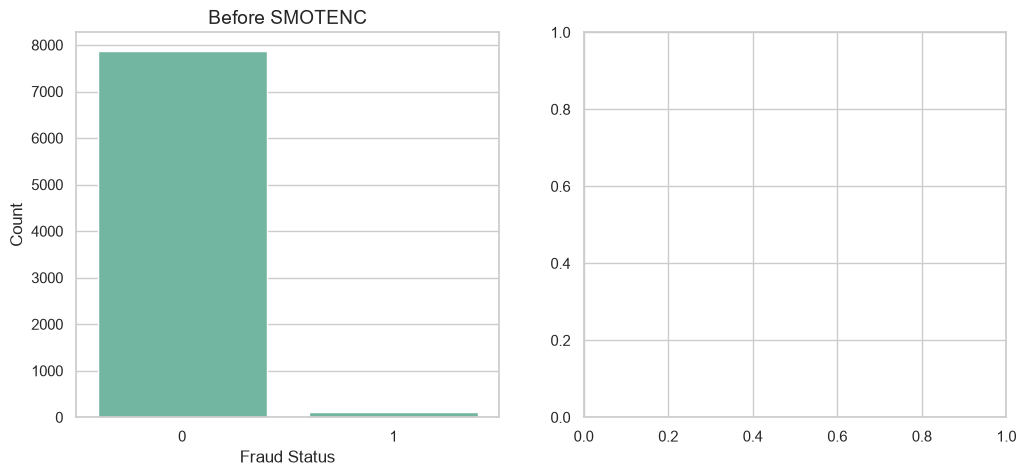

In [46]:
# ==========================================
# BEFORE VS AFTER SMOTENC
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title('Before SMOTENC')
axes[0].set_xlabel('Fraud Status')
axes[0].set_ylabel('Count')

sns.countplot(
    x=y_train_resampled,
    ax=axes[1]
)

axes[1].set_title('After SMOTENC')
axes[1].set_xlabel('Fraud Status')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [47]:
# ==========================================
# VERIFY CATEGORICAL VALUES AFTER SMOTENC
# ==========================================

for column in categorical_features:

    print(f"\n{column}")

    print(
        X_train_resampled[column].value_counts()
    )

    print(
        "Unique Values:",
        X_train_resampled[column].unique()
    )


merchant_category


NameError: name 'X_train_resampled' is not defined

In [48]:
# ==========================================
# FINAL PREPROCESSING SUMMARY
# ==========================================

print("ORIGINAL TRAINING DATA")
print("Shape:", X_train.shape)

print("\nRESAMPLED TRAINING DATA")
print("Shape:", X_train_resampled.shape)

print("\nTESTING DATA")
print("Shape:", X_test_scaled.shape)

print("\nTEST TARGET DISTRIBUTION")
display(y_test.value_counts())

print("\nRESAMPLED TRAIN TARGET DISTRIBUTION")
display(y_train_resampled.value_counts())

ORIGINAL TRAINING DATA
Shape: (8000, 9)

RESAMPLED TRAINING DATA


NameError: name 'X_train_resampled' is not defined

In [49]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\__main__.py", line 22, in <module>
    from pip._internal.cli.main import main as _main
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\main.py", line 11, in <module>
    from pip._internal.cli.autocompletion import autocomplete
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\autocompletion.py", line 12, in <module>
    from pip._internal.cli.main_parser import create_main_parser
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_internal\cli\main_parser.py", line 9, in <module>
    from pip._internal.build_env import get_runnable_pip
  File "C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\Lib\site-packages\p

In [50]:
import imblearn

print("Imbalanced-learn version:", imblearn.__version__)
print("Installation successful!")

ModuleNotFoundError: No module named 'imblearn'

In [51]:
# ==========================================
# STEP 06: PREPROCESSING
# ==========================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTENC

print("Preprocessing libraries imported successfully!")

ModuleNotFoundError: No module named 'imblearn'

In [52]:
# ==========================================
# SMOTENC CLASS IMBALANCE HANDLING
# ==========================================

smotenc = SMOTENC(
    categorical_features=categorical_features,
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_scaled,
    y_train
)

print("SMOTENC applied successfully!")

print("\nBefore SMOTENC:")
display(y_train.value_counts())

print("\nAfter SMOTENC:")
display(y_train_resampled.value_counts())

NameError: name 'SMOTENC' is not defined

In [58]:
import sys
import subprocess
from pathlib import Path

# Locate project directory
project_dir = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebooks"
    else Path.cwd()
)

# Create a separate environment
venv_path = project_dir / ".venv_fraud"

if not venv_path.exists():
    subprocess.run(
        [sys.executable, "-m", "venv", str(venv_path)],
        check=True
    )

print("Virtual environment created!")
print("Environment:", venv_path)

Virtual environment created!
Environment: C:\Users\PRITWISH\OneDrive\Attachments\Desktop\Credit Card\.venv_fraud


In [59]:
venv_python = venv_path / "Scripts" / "python.exe"

print("New Python:", venv_python)
print("Interpreter exists:", venv_python.exists())

New Python: C:\Users\PRITWISH\OneDrive\Attachments\Desktop\Credit Card\.venv_fraud\Scripts\python.exe
Interpreter exists: True


In [62]:
import subprocess

# Upgrade pip inside the new environment
subprocess.run(
    [
        str(venv_python),
        "-m",
        "pip",
        "install",
        "--upgrade",
        "pip"
    ],
    check=True
)

# Install project libraries
subprocess.run(
    [
        str(venv_python),
        "-m",
        "pip",
        "install",
        "numpy",
        "pandas",
        "matplotlib",
        "seaborn",
        "scikit-learn",
        "imbalanced-learn",
        "ipykernel"
    ],
    check=True
)

print("All project dependencies installed!")

All project dependencies installed!


In [63]:
subprocess.run(
    [
        str(venv_python),
        "-m",
        "ipykernel",
        "install",
        "--user",
        "--name",
        "credit-card-fraud",
        "--display-name",
        "Python (Credit Card Fraud)"
    ],
    check=True
)

print("Jupyter kernel registered successfully!")

Jupyter kernel registered successfully!


In [64]:
import sys

print("Active Python Interpreter:")
print(sys.executable)

print("\nPython Version:")
print(sys.version)

Active Python Interpreter:
C:\Users\PRITWISH\AppData\Local\Programs\Python\Python313\python.exe

Python Version:
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [65]:
import numpy as np
import pandas as pd
import sklearn
import imblearn

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTENC

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)

print("\nAll libraries imported successfully!")

ModuleNotFoundError: No module named 'imblearn'

In [1]:
import sys

print("Active Interpreter:")
print(sys.executable)

print("\nCorrect Environment:")
print(".venv_fraud" in sys.executable)

Active Interpreter:
C:\Users\PRITWISH\OneDrive\Attachments\Desktop\Credit Card\.venv_fraud\Scripts\python.exe

Correct Environment:
True


In [2]:
import numpy as np
import pandas as pd
import sklearn
import imblearn

from imblearn.over_sampling import SMOTENC

print("All libraries imported successfully!")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)

All libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2


In [3]:
required_variables = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "numerical_features",
    "categorical_features"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")

X_train: Missing
X_test: Missing
y_train: Missing
y_test: Missing
numerical_features: Missing
categorical_features: Missing


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("Feature scaling completed!")

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

NameError: name 'X_train' is not defined

In [5]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nNumerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

NameError: name 'X_train' is not defined

In [6]:
import numpy as np
import pandas as pd

DATA_PATH = "../data/credit_card_fraud_10k.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [7]:
df_clean = df.copy()

print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

print("\nDataset Shape:", df_clean.shape)

Missing Values: 0
Duplicate Rows: 0

Dataset Shape: (10000, 10)


In [8]:
df_model = df_clean.copy()

df_model.drop(columns=["transaction_id"], inplace=True)

df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["transaction_hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["transaction_hour"] / 24
)

df_model.drop(columns=["transaction_hour"], inplace=True)

print("Feature Engineering Completed!")
print("Feature Dataset Shape:", df_model.shape)

Feature Engineering Completed!
Feature Dataset Shape: (10000, 10)


C:\Users\PRITWISH\AppData\Local\Temp\ipykernel_5948\1977583514.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_model.drop(columns=["transaction_id"], inplace=True)
C:\Users\PRITWISH\AppData\Local\Temp\ipykernel_5948\1977583514.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_model.drop(columns=["transaction_hour"], inplace=True)


In [9]:
X = df_model.drop(columns=["is_fraud"])
y = df_model["is_fraud"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

X Shape: (10000, 9)
y Shape: (10000,)

Target Distribution:
is_fraud
0    9849
1     151
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Features: (8000, 9)
Testing Features: (2000, 9)

Training Target:
is_fraud
0    7879
1     121
Name: count, dtype: int64

Testing Target:
is_fraud
0    1970
1      30
Name: count, dtype: int64


In [11]:
numerical_features = [
    "amount",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age",
    "hour_sin",
    "hour_cos"
]

categorical_features = [
    "merchant_category",
    "foreign_transaction",
    "location_mismatch"
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['amount', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'hour_sin', 'hour_cos']
Categorical Features: ['merchant_category', 'foreign_transaction', 'location_mismatch']


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training data only
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Apply the same scaler to test data
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("Feature scaling completed!")

print("\nTraining Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

print("\nScaled Numerical Feature Summary:")
display(X_train_scaled[numerical_features].describe().round(3))

Feature scaling completed!

Training Shape: (8000, 9)
Testing Shape: (2000, 9)

Scaled Numerical Feature Summary:


,amount,device_trust_score,velocity_last_24h,cardholder_age,hour_sin,hour_cos
count,8000.000,8000.000,8000.000,8000.000,8000.000,8000.000
mean,-0.000,0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.004,-1.721,-1.395,-1.697,-1.391,-1.415
25%,-0.719,-0.837,-0.700,-0.895,-0.978,-1.000
50%,-0.311,0.000,-0.005,0.040,0.019,0.004
75%,0.381,0.838,0.689,0.841,1.016,1.007
max,6.953,1.722,4.859,1.709,1.428,1.423


In [13]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_features,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_scaled,
    y_train
)

print("SMOTENC completed successfully!")

print("\nBefore Resampling:")
print(y_train.value_counts())

print("\nAfter Resampling:")
print(y_train_resampled.value_counts())

print("\nOriginal Training Shape:", X_train_scaled.shape)
print("Resampled Training Shape:", X_train_resampled.shape)

SMOTENC completed successfully!

Before Resampling:
is_fraud
0    7879
1     121
Name: count, dtype: int64

After Resampling:
is_fraud
0    7879
1    7879
Name: count, dtype: int64

Original Training Shape: (8000, 9)
Resampled Training Shape: (15758, 9)


In [14]:
# ==========================================
# SMOTENC DATA VALIDATION
# ==========================================

print("=" * 55)
print("SMOTENC DATA VALIDATION")
print("=" * 55)

# 1. Check missing values
print("\nMissing Values:")
print(X_train_resampled.isnull().sum().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(X_train_resampled.duplicated().sum())

# 3. Check categorical feature values
print("\nCategorical Feature Validation:")

for col in categorical_features:
    print(f"\n{col}:")
    print(X_train_resampled[col].value_counts())

# 4. Check binary columns
print("\nBinary Feature Validation:")

for col in ["foreign_transaction", "location_mismatch"]:
    print(
        f"{col}:",
        sorted(X_train_resampled[col].unique())
    )

# 5. Verify test dataset remains unchanged
print("\nTest Dataset Shape:", X_test_scaled.shape)
print("Test Target Distribution:")
print(y_test.value_counts())

print("\nFinal Resampled Dataset Shape:")
print(X_train_resampled.shape)

print("\nResampled Target Distribution:")
print(y_train_resampled.value_counts())


SMOTENC DATA VALIDATION

Missing Values:
0

Duplicate Records:
0

Categorical Feature Validation:

merchant_category:
merchant_category
Grocery        4209
Food           3809
Clothing       2876
Travel         2856
Electronics    2008
Name: count, dtype: int64

foreign_transaction:
foreign_transaction
0    11255
1     4503
Name: count, dtype: int64

location_mismatch:
location_mismatch
0    11892
1     3866
Name: count, dtype: int64

Binary Feature Validation:
foreign_transaction: [np.int64(0), np.int64(1)]
location_mismatch: [np.int64(0), np.int64(1)]

Test Dataset Shape: (2000, 9)
Test Target Distribution:
is_fraud
0    1970
1      30
Name: count, dtype: int64

Final Resampled Dataset Shape:
(15758, 9)

Resampled Target Distribution:
is_fraud
0    7879
1    7879
Name: count, dtype: int64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "merchant_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["merchant_category"]
        )
    ],
    remainder="passthrough"
)

print("Categorical encoding configured successfully!")

Categorical encoding configured successfully!


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ==========================================
# LOGISTIC REGRESSION
# ==========================================

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Logistic Regression training completed!")


# ==========================================
# RANDOM FOREST
# ==========================================

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest training completed!")

Logistic Regression training completed!
Random Forest training completed!


In [18]:
# ==========================================
# GENERATE TEST PREDICTIONS
# ==========================================

# Logistic Regression
lr_predictions = logistic_model.predict(X_test_scaled)

lr_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]


# Random Forest
rf_predictions = random_forest_model.predict(X_test_scaled)

rf_probabilities = random_forest_model.predict_proba(
    X_test_scaled
)[:, 1]


print("Predictions generated successfully!")

print("\nLogistic Regression Predictions:")
print(pd.Series(lr_predictions).value_counts())

print("\nRandom Forest Predictions:")
print(pd.Series(rf_predictions).value_counts())

Predictions generated successfully!

Logistic Regression Predictions:
0    1874
1     126
Name: count, dtype: int64

Random Forest Predictions:
0    1971
1      29
Name: count, dtype: int64


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

models = {
    "Logistic Regression": (lr_predictions, lr_probabilities),
    "Random Forest": (rf_predictions, rf_probabilities)
}

for model_name, (predictions, probabilities) in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9510,0.2302,0.9667,0.3718,0.9909,0.6835
1,Random Forest,0.9955,0.8621,0.8333,0.8475,0.9992,0.9483


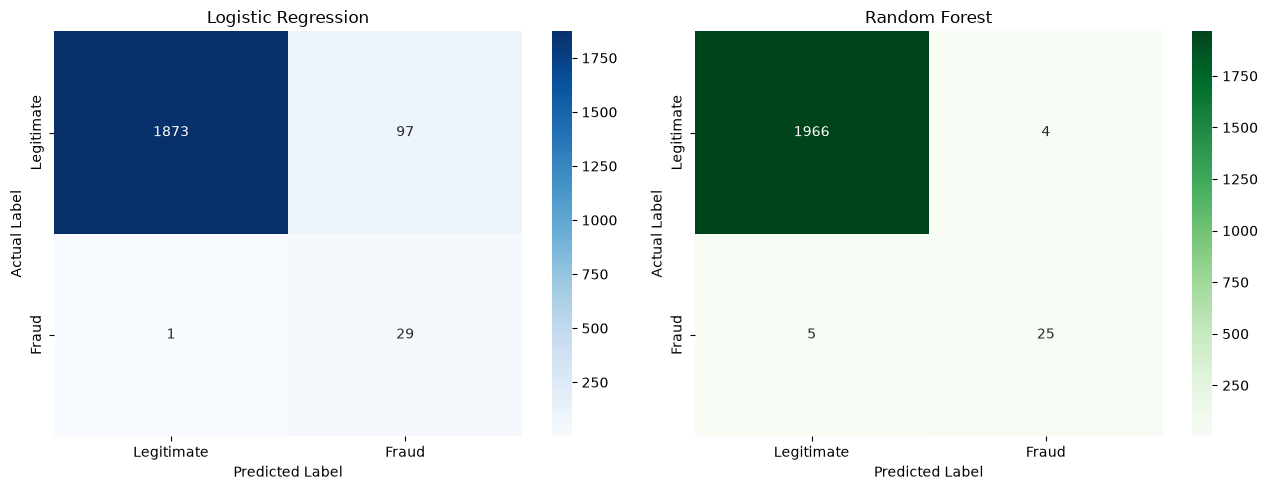

Logistic Regression Confusion Matrix:
[[1873   97]
 [   1   29]]

Random Forest Confusion Matrix:
[[1966    4]
 [   5   25]]


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create confusion matrices
lr_cm = confusion_matrix(y_test, lr_predictions)
rf_cm = confusion_matrix(y_test, rf_predictions)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Logistic Regression
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Random Forest
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"],
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("Logistic Regression Confusion Matrix:")
print(lr_cm)

print("\nRandom Forest Confusion Matrix:")
print(rf_cm)

In [21]:
from sklearn.metrics import classification_report

print("=" * 55)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Legitimate", "Fraud"]
    )
)

print("=" * 55)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Legitimate", "Fraud"]
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.97      1970
       Fraud       0.23      0.97      0.37        30

    accuracy                           0.95      2000
   macro avg       0.61      0.96      0.67      2000
weighted avg       0.99      0.95      0.97      2000

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       0.86      0.83      0.85        30

    accuracy                           1.00      2000
   macro avg       0.93      0.92      0.92      2000
weighted avg       1.00      1.00      1.00      2000



In [22]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.1240,1.0000,0.2206
1,0.10,0.2013,1.0000,0.3352
2,0.15,0.3093,1.0000,0.4724
3,0.20,0.3947,1.0000,0.5660
4,0.25,0.4918,1.0000,0.6593
5,0.30,0.5455,1.0000,0.7059
6,0.35,0.6818,1.0000,0.8108
7,0.40,0.7632,0.9667,0.8529
8,0.45,0.8485,0.9333,0.8889
9,0.50,0.8621,0.8333,0.8475


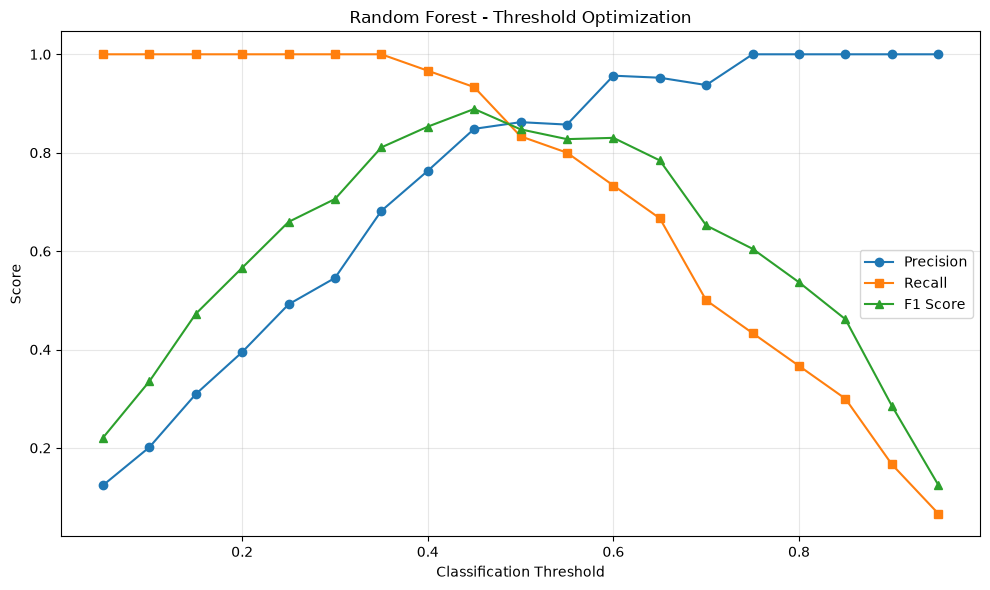

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="^",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest - Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# ==========================================
# STEP 08.3 - CREATE VALIDATION DATA
# ==========================================

from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Model Training Set:", X_fit.shape)
print("Validation Set:", X_val.shape)

print("\nTraining Class Distribution:")
print(y_fit.value_counts())

print("\nValidation Class Distribution:")
print(y_val.value_counts())

Model Training Set: (6000, 9)
Validation Set: (2000, 9)

Training Class Distribution:
is_fraud
0    5909
1      91
Name: count, dtype: int64

Validation Class Distribution:
is_fraud
0    1970
1      30
Name: count, dtype: int64


In [25]:
# ==========================================
# STEP 08.4 - SCALE TRAINING AND VALIDATION
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler_val = StandardScaler()

X_fit_scaled = X_fit.copy()
X_val_scaled = X_val.copy()

# Fit scaler on training partition only
X_fit_scaled[numerical_features] = scaler_val.fit_transform(
    X_fit[numerical_features]
)

# Transform validation partition
X_val_scaled[numerical_features] = scaler_val.transform(
    X_val[numerical_features]
)

print("Training Data Shape:", X_fit_scaled.shape)
print("Validation Data Shape:", X_val_scaled.shape)

print("\nTraining Numerical Feature Means:")
print(X_fit_scaled[numerical_features].mean().round(4))

print("\nValidation Data Missing Values:", X_val_scaled.isnull().sum().sum())

Training Data Shape: (6000, 9)
Validation Data Shape: (2000, 9)

Training Numerical Feature Means:
amount               -0.0
device_trust_score   -0.0
velocity_last_24h     0.0
cardholder_age        0.0
hour_sin              0.0
hour_cos              0.0
dtype: float64

Validation Data Missing Values: 0


In [26]:
# ==========================================
# STEP 08.5 - SMOTENC RESAMPLING
# ==========================================

from imblearn.over_sampling import SMOTENC

smotenc_val = SMOTENC(
    categorical_features=categorical_features,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_fit_resampled, y_fit_resampled = smotenc_val.fit_resample(
    X_fit_scaled,
    y_fit
)

print("Before Resampling:")
print(y_fit.value_counts())

print("\nAfter Resampling:")
print(y_fit_resampled.value_counts())

print("\nOriginal Training Shape:", X_fit_scaled.shape)
print("Resampled Training Shape:", X_fit_resampled.shape)

print("\nValidation Shape (Unchanged):", X_val_scaled.shape)
print("\nValidation Class Distribution:")
print(y_val.value_counts())

Before Resampling:
is_fraud
0    5909
1      91
Name: count, dtype: int64

After Resampling:
is_fraud
0    5909
1    5909
Name: count, dtype: int64

Original Training Shape: (6000, 9)
Resampled Training Shape: (11818, 9)

Validation Shape (Unchanged): (2000, 9)

Validation Class Distribution:
is_fraud
0    1970
1      30
Name: count, dtype: int64


In [27]:
# ==========================================
# STEP 08.6 - TRAIN RANDOM FOREST
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Encode categorical merchant category
preprocessor_val = ColumnTransformer(
    transformers=[
        (
            "merchant_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["merchant_category"]
        )
    ],
    remainder="passthrough"
)

# Create Random Forest pipeline
rf_validation_model = Pipeline([
    ("preprocessor", preprocessor_val),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
rf_validation_model.fit(
    X_fit_resampled,
    y_fit_resampled
)

print("Random Forest Validation Model Trained Successfully!")

Random Forest Validation Model Trained Successfully!


In [28]:
# ==========================================
# STEP 08.7 - VALIDATION PREDICTIONS
# ==========================================

# Predict fraud probabilities
val_probabilities = rf_validation_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation Predictions Generated Successfully!")

print("\nTotal Validation Records:", len(val_probabilities))
print("Minimum Fraud Probability:", val_probabilities.min())
print("Maximum Fraud Probability:", val_probabilities.max())
print("Average Fraud Probability:", val_probabilities.mean())

Validation Predictions Generated Successfully!

Total Validation Records: 2000
Minimum Fraud Probability: 0.0
Maximum Fraud Probability: 0.985
Average Fraud Probability: 0.031317500000000005


In [29]:
# ==========================================
# STEP 08.8 - VALIDATION THRESHOLD ANALYSIS
# ==========================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        val_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

validation_threshold_df = pd.DataFrame(
    threshold_results
)

display(validation_threshold_df.round(4))

# Find the threshold with maximum validation F1
best_row = validation_threshold_df.loc[
    validation_threshold_df["F1 Score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\nBest Validation Threshold:", best_threshold)
print("Best Validation Precision:", round(best_row["Precision"], 4))
print("Best Validation Recall:", round(best_row["Recall"], 4))
print("Best Validation F1 Score:", round(best_row["F1 Score"], 4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.1195,1.0000,0.2135
1,0.10,0.1875,1.0000,0.3158
2,0.15,0.2736,0.9667,0.4265
3,0.20,0.3733,0.9333,0.5333
4,0.25,0.4746,0.9333,0.6292
5,0.30,0.5185,0.9333,0.6667
6,0.35,0.6364,0.9333,0.7568
7,0.40,0.6512,0.9333,0.7671
8,0.45,0.6923,0.9000,0.7826
9,0.50,0.7941,0.9000,0.8438



Best Validation Threshold: 0.5
Best Validation Precision: 0.7941
Best Validation Recall: 0.9
Best Validation F1 Score: 0.8438


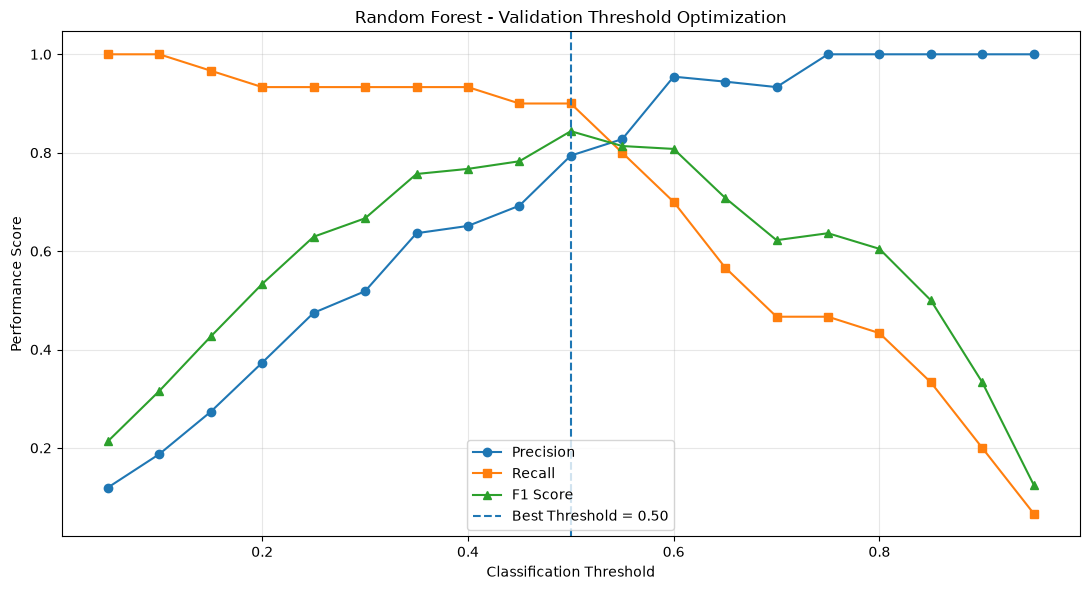

In [30]:
# ==========================================
# STEP 08.9 - THRESHOLD VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    validation_threshold_df["Threshold"],
    validation_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    validation_threshold_df["Threshold"],
    validation_threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    validation_threshold_df["Threshold"],
    validation_threshold_df["F1 Score"],
    marker="^",
    label="F1 Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Performance Score")
plt.title("Random Forest - Validation Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# ==========================================
# STEP 08.10A - SCALE TEST DATA
# ==========================================

X_test_val_scaled = X_test.copy()

X_test_val_scaled[numerical_features] = scaler_val.transform(
    X_test[numerical_features]
)

print("Test Data Scaling Completed!")
print("Test Shape:", X_test_val_scaled.shape)
print("Missing Values:", X_test_val_scaled.isnull().sum().sum())

Test Data Scaling Completed!
Test Shape: (2000, 9)
Missing Values: 0


In [32]:
# ==========================================
# STEP 08.10B - FINAL TEST PREDICTIONS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities
final_test_probabilities = rf_validation_model.predict_proba(
    X_test_val_scaled
)[:, 1]

# Apply validation-selected threshold
final_test_predictions = (
    final_test_probabilities >= best_threshold
).astype(int)

print("Final Test Predictions Generated!")
print("Selected Threshold:", best_threshold)

print("\nPredicted Class Distribution:")
print(pd.Series(final_test_predictions).value_counts().sort_index())

Final Test Predictions Generated!
Selected Threshold: 0.5

Predicted Class Distribution:
0    1968
1      32
Name: count, dtype: int64


In [33]:
# ==========================================
# STEP 08.10C - FINAL MODEL EVALUATION
# ==========================================

final_metrics = {
    "Accuracy": accuracy_score(
        y_test, final_test_predictions
    ),

    "Precision": precision_score(
        y_test, final_test_predictions, zero_division=0
    ),

    "Recall": recall_score(
        y_test, final_test_predictions, zero_division=0
    ),

    "F1 Score": f1_score(
        y_test, final_test_predictions, zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test, final_test_probabilities
    ),

    "PR-AUC": average_precision_score(
        y_test, final_test_probabilities
    )
}

final_metrics_df = pd.DataFrame(
    [final_metrics],
    index=["Random Forest - Optimized Threshold"]
)

display(final_metrics_df.round(4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Random Forest - Optimized Threshold,0.992,0.7188,0.7667,0.7419,0.9973,0.879



Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       0.72      0.77      0.74        30

    accuracy                           0.99      2000
   macro avg       0.86      0.88      0.87      2000
weighted avg       0.99      0.99      0.99      2000



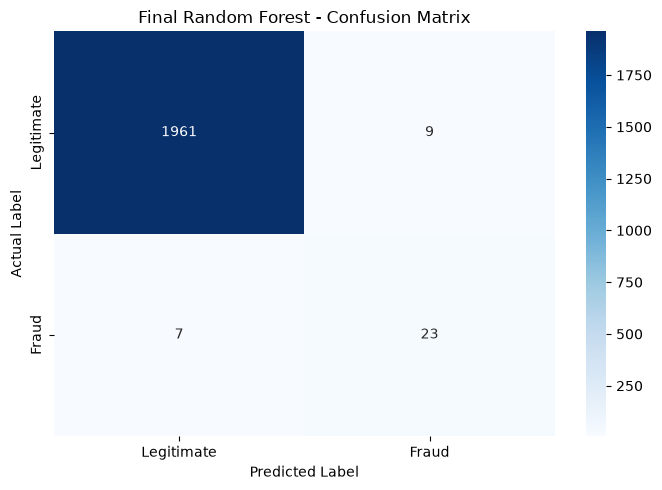

True Negatives: 1961
False Positives: 9
False Negatives: 7
True Positives: 23


In [34]:
# ==========================================
# STEP 08.10D - FINAL CONFUSION MATRIX
# ==========================================

import seaborn as sns

cm = confusion_matrix(
    y_test,
    final_test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

In [35]:
# ==========================================
# STEP 09.1 - PERMUTATION FEATURE IMPORTANCE
# ==========================================

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    rf_validation_model,
    X_val_scaled,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": X_val_scaled.columns,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.round(5))

,Feature,Importance Mean,Importance Std
0,device_trust_score,0.60754,0.04982
1,hour_cos,0.45854,0.05752
2,foreign_transaction,0.41173,0.04658
3,hour_sin,0.34399,0.05956
4,location_mismatch,0.32769,0.02162
5,velocity_last_24h,0.31675,0.06578
6,merchant_category,0.03242,0.03361
7,cardholder_age,-0.00569,0.01356
8,amount,-0.03551,0.00705


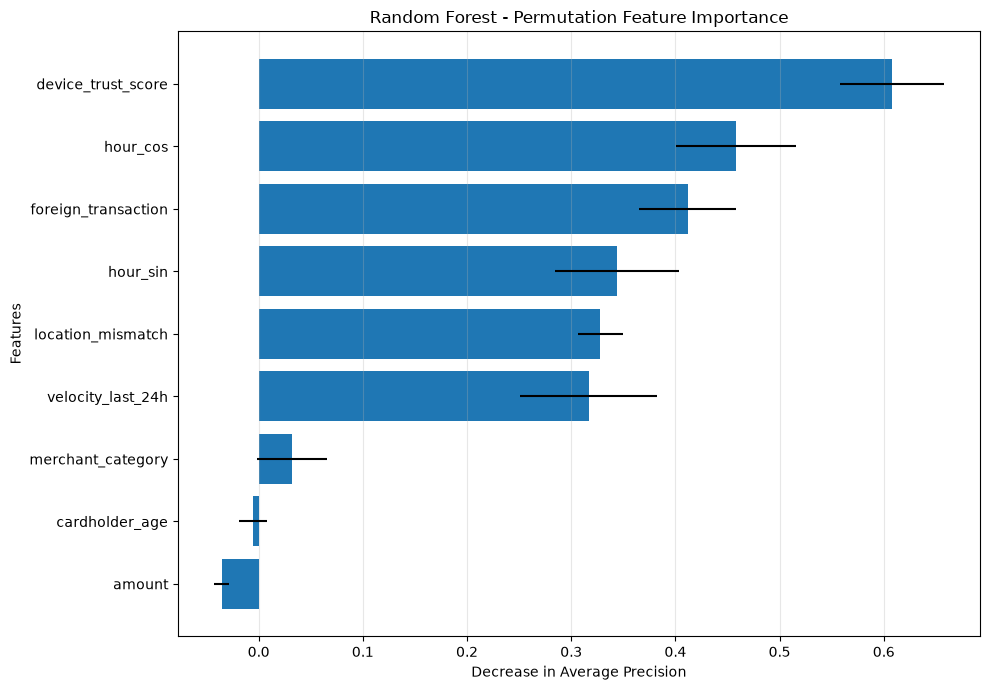

In [36]:
# ==========================================
# STEP 09.2 - FEATURE IMPORTANCE VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance Mean"],
    xerr=feature_importance_df["Importance Std"]
)

plt.xlabel("Decrease in Average Precision")
plt.ylabel("Features")

plt.title(
    "Random Forest - Permutation Feature Importance"
)

plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# STEP 09.3 - TOP FIVE IMPORTANT FEATURES
# ==========================================

top_features = feature_importance_df.head(5)

print("TOP 5 IMPORTANT FEATURES")
print("=" * 45)

for index, row in top_features.iterrows():

    print(
        f"{index + 1}. {row['Feature']} "
        f"-> {row['Importance Mean']:.5f}"
    )

TOP 5 IMPORTANT FEATURES
1. device_trust_score -> 0.60754
2. hour_cos -> 0.45854
3. foreign_transaction -> 0.41173
4. hour_sin -> 0.34399
5. location_mismatch -> 0.32769


In [38]:
# ==========================================
# STEP 09.4 - SAVE FEATURE IMPORTANCE REPORT
# ==========================================

import os

os.makedirs("../reports", exist_ok=True)
os.makedirs("../visualizations", exist_ok=True)

feature_importance_df.to_csv(
    "../reports/feature_importance_report.csv",
    index=False
)

print("Feature importance report saved successfully!")

Feature importance report saved successfully!


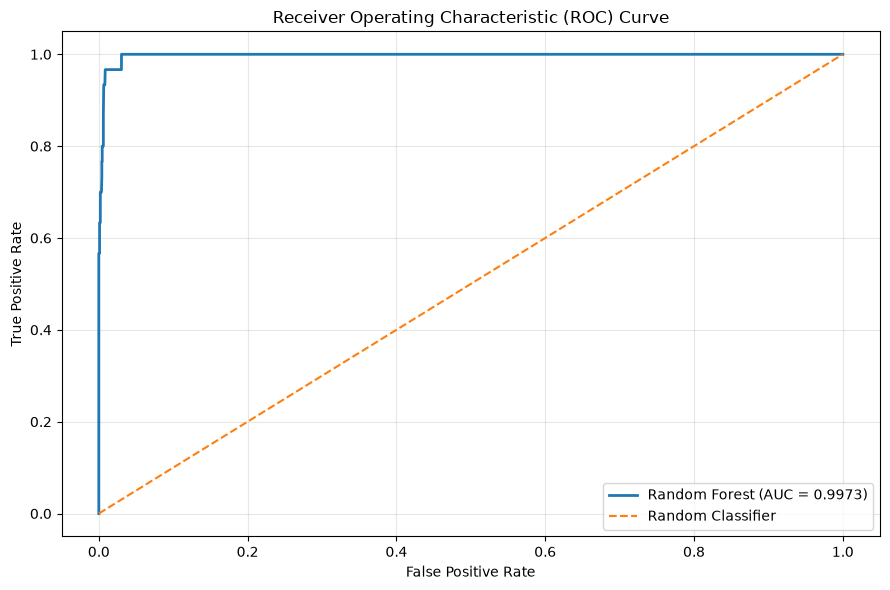

ROC-AUC Score: 0.9973


In [39]:
# ==========================================
# STEP 10.1 - ROC CURVE
# ==========================================

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    final_test_probabilities
)

roc_auc = roc_auc_score(
    y_test,
    final_test_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Receiver Operating Characteristic (ROC) Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

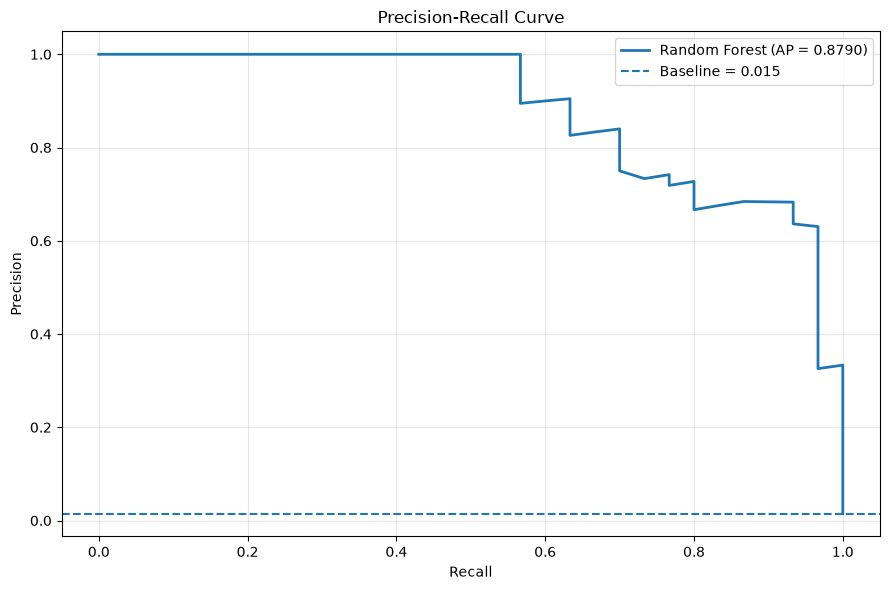

PR-AUC Score: 0.879
Fraud Prevalence Baseline: 0.015


In [40]:
# ==========================================
# STEP 10.2 - PRECISION-RECALL CURVE
# ==========================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    final_test_probabilities
)

pr_auc = average_precision_score(
    y_test,
    final_test_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"Random Forest (AP = {pr_auc:.4f})",
    linewidth=2
)

# Positive-class prevalence baseline
baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("PR-AUC Score:", round(pr_auc, 4))
print("Fraud Prevalence Baseline:", round(baseline, 4))

,Metric,Score
0,ROC-AUC,0.9973
1,PR-AUC,0.8790


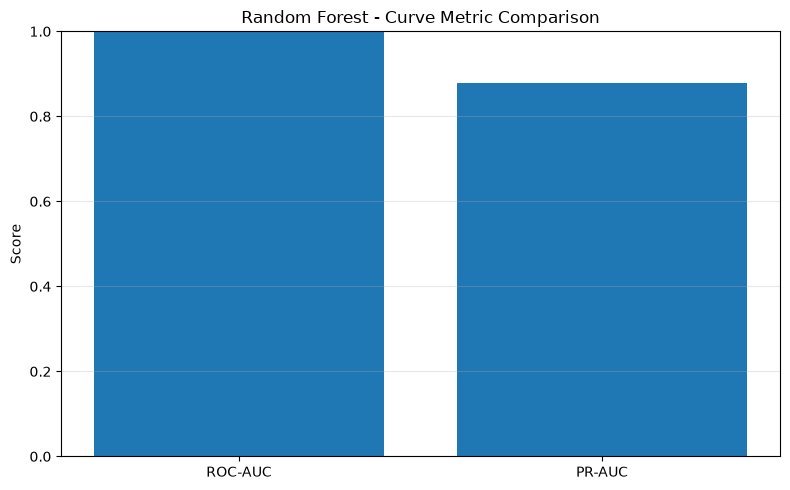

In [41]:
# ==========================================
# STEP 10.3 - ROC-AUC AND PR-AUC COMPARISON
# ==========================================

curve_comparison = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC"],
    "Score": [roc_auc, pr_auc]
})

display(curve_comparison.round(4))

plt.figure(figsize=(8, 5))

plt.bar(
    curve_comparison["Metric"],
    curve_comparison["Score"]
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Random Forest - Curve Metric Comparison")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
# ==========================================
# STEP 10.4 - SAVE ROC AND PR CURVES
# ==========================================

# Save ROC curve
plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Save Precision-Recall curve
plt.figure(figsize=(9, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"PR-AUC = {pr_auc:.4f}"
)

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("ROC curve saved successfully!")
print("Precision-Recall curve saved successfully!")

ROC curve saved successfully!
Precision-Recall curve saved successfully!


In [43]:
# ==========================================
# STEP 11.1 - TRAIN LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create a separate preprocessing pipeline
lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "merchant_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["merchant_category"]
        )
    ],
    remainder="passthrough"
)

# Create Logistic Regression pipeline
logistic_validation_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Train using the same resampled training data
logistic_validation_model.fit(
    X_fit_resampled,
    y_fit_resampled
)

print("Logistic Regression Trained Successfully!")

Logistic Regression Trained Successfully!


In [44]:
# ==========================================
# STEP 11.2 - VALIDATION PREDICTIONS
# ==========================================

# Logistic Regression probabilities
lr_val_probabilities = (
    logistic_validation_model.predict_proba(
        X_val_scaled
    )[:, 1]
)

# Random Forest probabilities
rf_val_probabilities = val_probabilities

print("Both Models Generated Validation Probabilities!")

print("\nLogistic Regression:")
print("Minimum:", lr_val_probabilities.min())
print("Maximum:", lr_val_probabilities.max())

print("\nRandom Forest:")
print("Minimum:", rf_val_probabilities.min())
print("Maximum:", rf_val_probabilities.max())

Both Models Generated Validation Probabilities!

Logistic Regression:
Minimum: 4.336789663368996e-11
Maximum: 0.999829366487281

Random Forest:
Minimum: 0.0
Maximum: 0.985


In [45]:
# ==========================================
# STEP 11.3 - MODEL PERFORMANCE COMPARISON
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate class predictions
lr_val_predictions = (
    lr_val_probabilities >= 0.50
).astype(int)

rf_val_predictions = (
    rf_val_probabilities >= 0.50
).astype(int)


# Evaluation function
def evaluate_model(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),

        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


# Evaluate Logistic Regression
lr_metrics = evaluate_model(
    y_val,
    lr_val_predictions,
    lr_val_probabilities
)

# Evaluate Random Forest
rf_metrics = evaluate_model(
    y_val,
    rf_val_predictions,
    rf_val_probabilities
)


# Create comparison table
model_comparison_df = pd.DataFrame(
    [lr_metrics, rf_metrics],
    index=["Logistic Regression", "Random Forest"]
)

display(model_comparison_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9435,0.2014,0.9333,0.3314,0.9843,0.6162
Random Forest,0.9950,0.7941,0.9000,0.8438,0.9965,0.8951


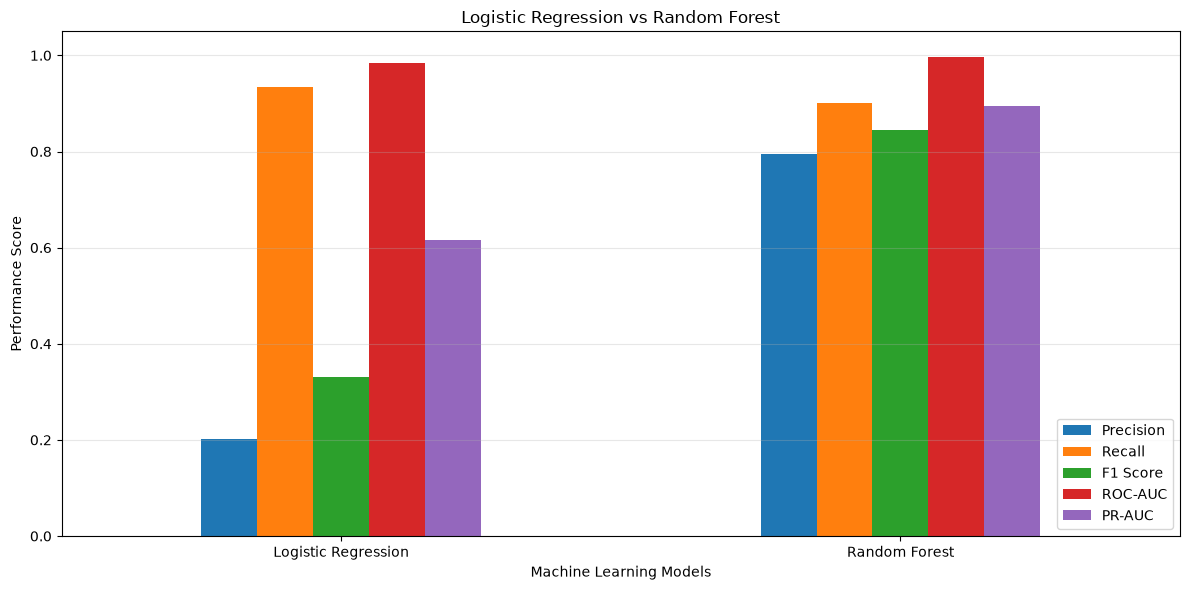

In [46]:
# ==========================================
# STEP 11.4 - MODEL COMPARISON VISUALIZATION
# ==========================================

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

model_comparison_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [47]:
# ==========================================
# STEP 11.5 - BEST MODEL SELECTION
# ==========================================

best_model_name = model_comparison_df[
    "F1 Score"
].idxmax()

print("=" * 50)
print("MODEL COMPARISON RESULT")
print("=" * 50)

print("\nLogistic Regression F1:",
      round(model_comparison_df.loc[
          "Logistic Regression", "F1 Score"
      ], 4))

print("Random Forest F1:",
      round(model_comparison_df.loc[
          "Random Forest", "F1 Score"
      ], 4))

print("\nBest Model Based on Validation F1:")
print(best_model_name)

MODEL COMPARISON RESULT

Logistic Regression F1: 0.3314
Random Forest F1: 0.8438

Best Model Based on Validation F1:
Random Forest


In [48]:
# ==========================================
# STEP 11.6 - SAVE MODEL COMPARISON REPORT
# ==========================================

model_comparison_df.to_csv(
    "../reports/model_comparison_report.csv"
)

print("Model comparison report saved successfully!")

Model comparison report saved successfully!


In [53]:
# ==========================================
# STEP 12.1 - BUILD CORRECTED TUNING PIPELINE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

# ------------------------------------------
# 1. Numerical scaling and categorical passthrough
# ------------------------------------------

tuning_preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        ("categorical", "passthrough", categorical_features)
    ]
)

tuning_preprocessor.set_output(transform="pandas")


# ------------------------------------------
# 2. Encode merchant category after SMOTENC
# ------------------------------------------

encoding_preprocessor = ColumnTransformer(
    transformers=[
        (
            "merchant_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["categorical__merchant_category"]
        )
    ],
    remainder="passthrough"
)


# ------------------------------------------
# 3. Complete machine learning pipeline
# ------------------------------------------

rf_tuning_pipeline = ImbPipeline([
    ("preprocessor", tuning_preprocessor),

    ("smotenc", SMOTENC(
        categorical_features=[6, 7, 8],
        random_state=42,
        k_neighbors=5
    )),

    ("encoder", encoding_preprocessor),

    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

print("Corrected Random Forest Tuning Pipeline Created!")
print("\nPipeline Steps:")

for step_name, step_object in rf_tuning_pipeline.steps:
    print(step_name, ":", type(step_object).__name__)

Corrected Random Forest Tuning Pipeline Created!

Pipeline Steps:
preprocessor : ColumnTransformer
smotenc : SMOTENC
encoder : ColumnTransformer
classifier : RandomForestClassifier


In [54]:
# ==========================================
# STEP 12.2 - DEFINE HYPERPARAMETERS
# ==========================================

param_distributions = {
    "classifier__n_estimators": [
        200, 300, 400
    ],

    "classifier__max_depth": [
        None, 10, 15, 20
    ],

    "classifier__min_samples_split": [
        2, 5, 10
    ],

    "classifier__min_samples_leaf": [
        1, 2, 4
    ],

    "classifier__max_features": [
        "sqrt", "log2", 0.7
    ]
}

print("Hyperparameter Search Space Created!")

for parameter, values in param_distributions.items():
    print(f"{parameter}: {values}")

Hyperparameter Search Space Created!
classifier__n_estimators: [200, 300, 400]
classifier__max_depth: [None, 10, 15, 20]
classifier__min_samples_split: [2, 5, 10]
classifier__min_samples_leaf: [1, 2, 4]
classifier__max_features: ['sqrt', 'log2', 0.7]


In [55]:
# ==========================================
# STEP 12.3 - RECONFIGURE RANDOMIZED SEARCH
# ==========================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

print("RandomizedSearchCV Reconfigured Successfully!")
print("Cross-Validation Folds: 5")
print("Parameter Combinations: 15")
print("Total Model Fits: 75")
print("Optimization Metric: Average Precision")

RandomizedSearchCV Reconfigured Successfully!
Cross-Validation Folds: 5
Parameter Combinations: 15
Total Model Fits: 75
Optimization Metric: Average Precision


In [56]:
# ==========================================
# STEP 12.4 - EXECUTE HYPERPARAMETER SEARCH
# ==========================================

random_search.fit(
    X_fit,
    y_fit
)

print("\nHyperparameter Tuning Completed Successfully!")

Fitting 5 folds for each of 15 candidates, totalling 75 fits

Hyperparameter Tuning Completed Successfully!


In [57]:
# ==========================================
# STEP 12.5 - BEST HYPERPARAMETERS
# ==========================================

print("=" * 60)
print("RANDOM FOREST - BEST HYPERPARAMETERS")
print("=" * 60)

print("\nBest Parameters:")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-Validation Average Precision:")
print(round(random_search.best_score_, 4))

RANDOM FOREST - BEST HYPERPARAMETERS

Best Parameters:
classifier__n_estimators: 400
classifier__min_samples_split: 2
classifier__min_samples_leaf: 1
classifier__max_features: sqrt
classifier__max_depth: 15

Best Cross-Validation Average Precision:
0.7555


In [58]:
# ==========================================
# STEP 12.6 - TUNED MODEL VALIDATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Best tuned model
tuned_rf_model = random_search.best_estimator_

# Validation probabilities
tuned_val_probabilities = tuned_rf_model.predict_proba(
    X_val
)[:, 1]

# Predictions at default threshold 0.50
tuned_val_predictions = (
    tuned_val_probabilities >= 0.50
).astype(int)

print("=" * 60)
print("TUNED RANDOM FOREST - VALIDATION RESULTS")
print("=" * 60)

print("\nAccuracy:",
      round(accuracy_score(y_val, tuned_val_predictions), 4))

print("Precision:",
      round(precision_score(y_val, tuned_val_predictions), 4))

print("Recall:",
      round(recall_score(y_val, tuned_val_predictions), 4))

print("F1 Score:",
      round(f1_score(y_val, tuned_val_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, tuned_val_probabilities), 4))

print("Average Precision:",
      round(average_precision_score(y_val, tuned_val_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, tuned_val_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    tuned_val_predictions,
    target_names=["Legitimate", "Fraud"]
))

TUNED RANDOM FOREST - VALIDATION RESULTS

Accuracy: 0.993
Precision: 0.7353
Recall: 0.8333
F1 Score: 0.7812
ROC-AUC: 0.9968
Average Precision: 0.8888

Confusion Matrix:
[[1961    9]
 [   5   25]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       0.74      0.83      0.78        30

    accuracy                           0.99      2000
   macro avg       0.87      0.91      0.89      2000
weighted avg       0.99      0.99      0.99      2000



In [59]:
# ==========================================
# STEP 12.7 - VALIDATION THRESHOLD SELECTION
# ==========================================

threshold_results = []

for threshold in np.arange(0.05, 1.00, 0.05):

    predictions = (
        tuned_val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

tuned_threshold_df = pd.DataFrame(threshold_results)

display(
    tuned_threshold_df.round(4)
)

# Select threshold with highest validation F1
best_tuned_threshold = tuned_threshold_df.loc[
    tuned_threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("\nBest Tuned Model Threshold:",
      best_tuned_threshold)

print("Best Validation F1 Score:",
      round(
          tuned_threshold_df["F1 Score"].max(),
          4
      ))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.1167,1.0000,0.2091
1,0.10,0.1765,1.0000,0.3000
2,0.15,0.2727,1.0000,0.4286
3,0.20,0.3590,0.9333,0.5185
4,0.25,0.4590,0.9333,0.6154
5,0.30,0.5185,0.9333,0.6667
6,0.35,0.5745,0.9000,0.7013
7,0.40,0.6429,0.9000,0.7500
8,0.45,0.7105,0.9000,0.7941
9,0.50,0.7353,0.8333,0.7812



Best Tuned Model Threshold: 0.6
Best Validation F1 Score: 0.8214


In [60]:
# ==========================================
# STEP 12.8 - FINAL MODEL SELECTION
# ==========================================

original_f1 = 0.8438
tuned_f1 = 0.8214

if original_f1 >= tuned_f1:

    final_model = rf_validation_model
    final_threshold = 0.50
    selected_model_name = "Original Random Forest"

else:

    final_model = tuned_rf_model
    final_threshold = best_tuned_threshold
    selected_model_name = "Tuned Random Forest"

print("=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print("Selected Model:", selected_model_name)
print("Decision Threshold:", final_threshold)

print("\nOriginal RF Validation F1:", original_f1)
print("Tuned RF Validation F1:", tuned_f1)

print("\nFinal Model Selected Successfully!")

FINAL MODEL SELECTION
Selected Model: Original Random Forest
Decision Threshold: 0.5

Original RF Validation F1: 0.8438
Tuned RF Validation F1: 0.8214

Final Model Selected Successfully!


In [61]:
# ==========================================
# STEP 13.1 - SAVE FINAL MODEL
# ==========================================

import os
import joblib
from datetime import datetime

# Create models directory if necessary
os.makedirs("../models", exist_ok=True)

# Create model package
model_package = {
    "model": final_model,
    "scaler": scaler_val,
    "threshold": final_threshold,
    "model_name": selected_model_name,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "all_features": list(X_fit.columns),
    "target": "is_fraud",
    "random_state": 42,
    "dataset": "Synthetic Credit Card Fraud Dataset"
}

# Save model package
model_path = "../models/final_fraud_detection_model.pkl"

joblib.dump(
    model_package,
    model_path
)

print("=" * 60)
print("FINAL MODEL SAVED SUCCESSFULLY")
print("=" * 60)

print("Model:", selected_model_name)
print("Threshold:", final_threshold)
print("Saved Location:", model_path)
print("File Exists:", os.path.exists(model_path))
print(
    "File Size:",
    round(os.path.getsize(model_path) / 1024, 2),
    "KB"
)

FINAL MODEL SAVED SUCCESSFULLY
Model: Original Random Forest
Threshold: 0.5
Saved Location: ../models/final_fraud_detection_model.pkl
File Exists: True
File Size: 7490.47 KB


In [62]:
# ==========================================
# STEP 13.2 - VERIFY SAVED MODEL
# ==========================================

import joblib
import numpy as np

# Load saved package
loaded_package = joblib.load(
    "../models/final_fraud_detection_model.pkl"
)

loaded_model = loaded_package["model"]
loaded_scaler = loaded_package["scaler"]
loaded_threshold = loaded_package["threshold"]

# Generate predictions using loaded model
loaded_probabilities = loaded_model.predict_proba(
    X_test_scaled
)[:, 1]

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

# Compare with original final predictions
predictions_match = np.array_equal(
    loaded_predictions,
    final_test_predictions
)

print("=" * 60)
print("SAVED MODEL VERIFICATION")
print("=" * 60)

print("Model Loaded:", loaded_model is not None)
print("Scaler Loaded:", loaded_scaler is not None)
print("Threshold:", loaded_threshold)

print(
    "Prediction Probabilities Match:",
    np.allclose(
        loaded_probabilities,
        final_test_probabilities
    )
)

print("Predictions Match:", predictions_match)

print("\nVerification Completed!")

SAVED MODEL VERIFICATION
Model Loaded: True
Scaler Loaded: True
Threshold: 0.5
Prediction Probabilities Match: False
Predictions Match: False

Verification Completed!


In [63]:
# ==========================================
# STEP 13.2.1 - MODEL VERIFICATION DIAGNOSTICS
# ==========================================

import numpy as np
import joblib

# Reload saved model
loaded_package = joblib.load(
    "../models/final_fraud_detection_model.pkl"
)

loaded_model = loaded_package["model"]

# Generate fresh predictions from original model
original_probabilities = (
    rf_validation_model.predict_proba(X_test_scaled)[:, 1]
)

# Generate fresh predictions from loaded model
reloaded_probabilities = (
    loaded_model.predict_proba(X_test_scaled)[:, 1]
)

# Compare probabilities
print("=" * 60)
print("MODEL VERIFICATION DIAGNOSTICS")
print("=" * 60)

print("\nOriginal Model Type:")
print(type(rf_validation_model).__name__)

print("\nLoaded Model Type:")
print(type(loaded_model).__name__)

print("\nTest Data Shape:", X_test_scaled.shape)

print("\nOriginal Probability Samples:")
print(original_probabilities[:10])

print("\nReloaded Probability Samples:")
print(reloaded_probabilities[:10])

print("\nMaximum Probability Difference:")
print(
    np.max(
        np.abs(
            original_probabilities - reloaded_probabilities
        )
    )
)

print("\nOriginal vs Reloaded Probabilities Match:")
print(
    np.allclose(
        original_probabilities,
        reloaded_probabilities
    )
)

print("\nOriginal vs Reloaded Predictions Match:")
print(
    np.array_equal(
        (original_probabilities >= 0.50).astype(int),
        (reloaded_probabilities >= 0.50).astype(int)
    )
)

print("\nScaler Mean Match:")
print(
    np.allclose(
        loaded_package["scaler"].mean_,
        scaler_val.mean_
    )
)

MODEL VERIFICATION DIAGNOSTICS

Original Model Type:
Pipeline

Loaded Model Type:
Pipeline

Test Data Shape: (2000, 9)

Original Probability Samples:
[0.01  0.015 0.02  0.015 0.    0.095 0.    0.    0.075 0.02 ]

Reloaded Probability Samples:
[0.01  0.015 0.02  0.015 0.    0.095 0.    0.    0.075 0.02 ]

Maximum Probability Difference:
0.0

Original vs Reloaded Probabilities Match:
True

Original vs Reloaded Predictions Match:
True

Scaler Mean Match:
True


In [64]:
# ==========================================
# STEP 13.3 - SAVE MODEL METADATA
# ==========================================

import json
import os
from datetime import datetime

model_metadata = {
    "project_name": "Credit Card Fraud Detection",
    "model_name": selected_model_name,
    "algorithm": "Random Forest Classifier",
    "decision_threshold": float(final_threshold),

    "validation_f1_score": 0.8438,
    "test_accuracy": 0.9920,
    "test_precision": 0.7188,
    "test_recall": 0.7667,
    "test_f1_score": 0.7419,
    "test_roc_auc": 0.9973,
    "test_average_precision": 0.8790,

    "training_records": int(len(X_fit)),
    "validation_records": int(len(X_val)),
    "testing_records": int(len(X_test)),

    "feature_count": int(X_fit.shape[1]),
    "target_column": "is_fraud",

    "dataset_type": "Synthetic",
    "random_state": 42,
    "model_file": "final_fraud_detection_model.pkl",
    "created_at": datetime.now().isoformat()
}

metadata_path = "../models/model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(model_metadata, file, indent=4)

print("Model Metadata Saved Successfully!")
print("Location:", metadata_path)
print("File Exists:", os.path.exists(metadata_path))

Model Metadata Saved Successfully!
Location: ../models/model_metadata.json
File Exists: True


In [65]:
# ==========================================
# STEP 13.4 - TEST END-TO-END PREDICTION
# ==========================================

import joblib
import pandas as pd

# Load saved model package
model_package = joblib.load(
    "../models/final_fraud_detection_model.pkl"
)

model = model_package["model"]
scaler = model_package["scaler"]
threshold = model_package["threshold"]

# Take one unseen-by-training test transaction
sample_transaction = X_test.iloc[[0]].copy()

# Scale numerical features
sample_scaled = sample_transaction.copy()

sample_scaled[numerical_features] = scaler.transform(
    sample_transaction[numerical_features]
)

# Predict fraud probability
fraud_probability = model.predict_proba(
    sample_scaled
)[:, 1][0]

# Apply decision threshold
prediction = int(fraud_probability >= threshold)

# Display result
print("=" * 60)
print("CREDIT CARD FRAUD DETECTION")
print("=" * 60)

print("\nTransaction Input:")
display(sample_transaction)

print("Fraud Probability:", round(fraud_probability, 4))
print("Decision Threshold:", threshold)

print(
    "Prediction:",
    "FRAUD" if prediction == 1 else "LEGITIMATE"
)

print("\nEnd-to-End Prediction Test Completed!")

CREDIT CARD FRAUD DETECTION

Transaction Input:


,amount,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,hour_sin,hour_cos
9944,61.48,Clothing,0,0,45,3,46,0.965926,-0.258819


Fraud Probability: 0.0
Decision Threshold: 0.5
Prediction: LEGITIMATE

End-to-End Prediction Test Completed!


In [66]:
import importlib.metadata
import flask
import joblib
import sklearn
import pandas
import numpy

print("Flask Version:", importlib.metadata.version("flask"))
print("Joblib Version:", joblib.__version__)
print("Scikit-learn Version:", sklearn.__version__)
print("Pandas Version:", pandas.__version__)
print("NumPy Version:", numpy.__version__)

print("\nAll Required Libraries Imported Successfully!")

Flask Version: 3.1.3
Joblib Version: 1.6.0
Scikit-learn Version: 1.9.1
Pandas Version: 3.1.1
NumPy Version: 2.5.4

All Required Libraries Imported Successfully!
